In [1]:
import numpy as np
import matplotlib.pyplot as plt
import batman

In [8]:
data = np.loadtxt(
    "../data/apjladf06ft3_mrt.txt",
    skiprows=15
)

t = data[:, 0] + 2454833
flux = data[:, 2]

In [3]:
t0 = 2458055.0969

mask = np.abs(t - t0) < 0.8

t_transit = t[mask]
flux_transit = flux[mask]

print(len(t_transit))

67


In [4]:
params = batman.TransitParams()

params.t0 = t0

# approximately published values
params.per = 355.0
params.rp = 0.01368
params.a = 270.0

# circular, central transit for first test
params.inc = 90.0
params.ecc = 0.0
params.w = 90.0

# quadratic limb darkening
params.u = [0.56, 0.10]
params.limb_dark = "quadratic"

In [5]:
model = batman.TransitModel(
    params,
    t_transit,
    supersample_factor=10,
    exp_time=29.4 / (24 * 60)
)

model_flux = model.light_curve(params)

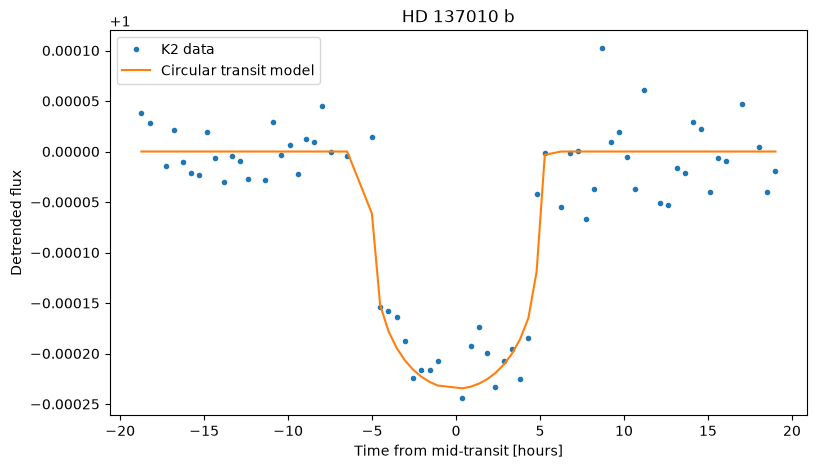

In [6]:
plt.figure(figsize=(9, 5))

plt.plot(
    (t_transit - t0) * 24,
    flux_transit,
    ".",
    label="K2 data"
)

plt.plot(
    (t_transit - t0) * 24,
    model_flux,
    "-",
    label="Circular transit model"
)

plt.xlabel("Time from mid-transit [hours]")
plt.ylabel("Detrended flux")
plt.title("HD 137010 b")
plt.legend()

plt.show()